<a href="https://colab.research.google.com/github/mdnasiruddinutshaw2003/Student-Score-Prediction-/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
url = "https://raw.githubusercontent.com/Chandana14314/student-score-prediction/main/score.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 10 Rows:")
display(df.head(10))

Dataset Shape:
(25, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes

Statistical Summary:


,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000



First 10 Rows:


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30
5,1.5,20
6,9.2,88
7,5.5,60
8,8.3,81
9,2.7,25


In [4]:
print("Missing Values:")
print(df.isnull().sum())

df = df.drop_duplicates()

df = df.dropna()

df['Hours'] = pd.to_numeric(df['Hours'], errors='coerce')
df['Scores'] = pd.to_numeric(df['Scores'], errors='coerce')

df = df.dropna()

df = df[
    (df['Hours'] >= 0) &
    (df['Scores'] >= 0) &
    (df['Scores'] <= 100)
]

print("\nAfter Data Cleaning:")
print(df.isnull().sum())

print("\nClean Dataset Shape:")
print(df.shape)

Missing Values:
Hours     0
Scores    0
dtype: int64

After Data Cleaning:
Hours     0
Scores    0
dtype: int64

Clean Dataset Shape:
(25, 2)


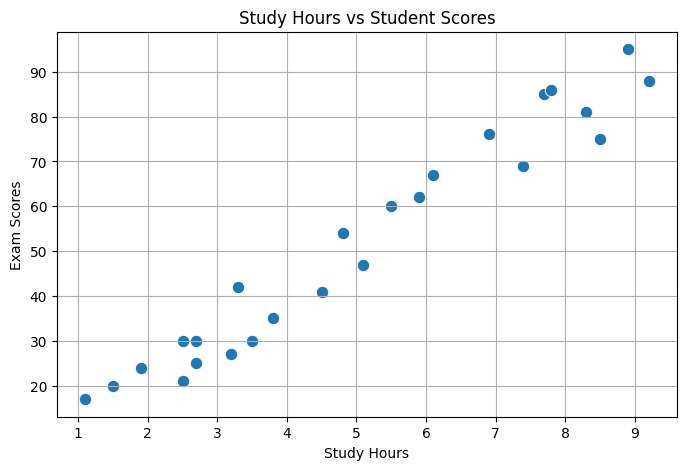

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Hours',
    y='Scores',
    data=df,
    s=80
)

plt.title("Study Hours vs Student Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Scores")

plt.grid(True)
plt.show()


In [6]:
X = df[['Hours']]
y = df['Scores']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nFeature:", X.columns.tolist())
print("Target: Scores")

Training Data: (20, 1)
Testing Data: (5, 1)

Feature: ['Hours']
Target: Scores


In [7]:
linear_model = LinearRegression()

tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

linear_model.fit(X_train, y_train)

tree_model.fit(X_train, y_train)

print("Linear Regression Training Completed!")
print("Decision Tree Regression Training Completed!")

Linear Regression Training Completed!
Decision Tree Regression Training Completed!


In [8]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree Regression": tree_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,3.9208,18.9432,4.3524,0.9678
1,Decision Tree Regression,4.8000,33.6778,5.8033,0.9428


In [9]:
cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='r2'
    )

    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean R2": scores.mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean R2
0,Linear Regression,0.7863,0.9789,0.9318,0.9660,0.9273,0.9181
1,Decision Tree Regression,0.7398,0.9695,0.8234,0.8688,0.9098,0.8623


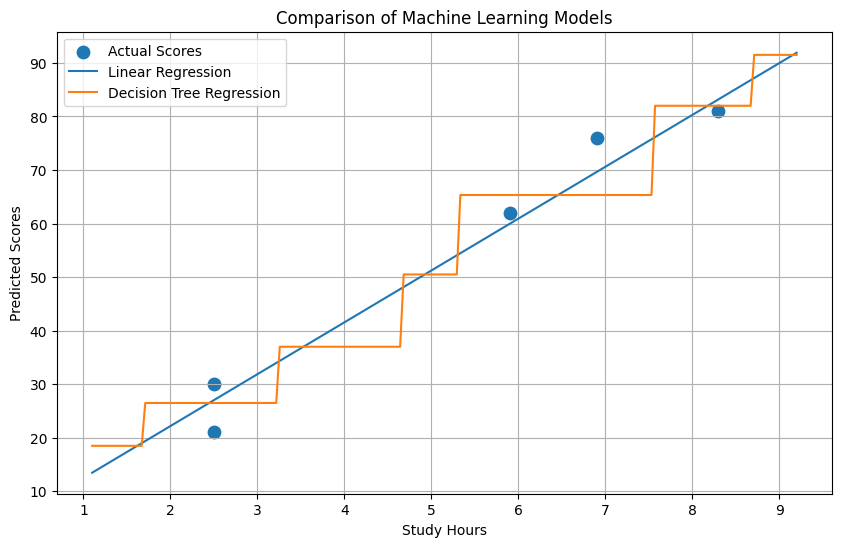

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test['Hours'],
    y_test,
    label="Actual Scores",
    s=80
)

hours_range = np.linspace(
    df['Hours'].min(),
    df['Hours'].max(),
    200
).reshape(-1, 1)

plt.plot(
    hours_range,
    linear_model.predict(hours_range),
    label="Linear Regression"
)

plt.plot(
    hours_range,
    tree_model.predict(hours_range),
    label="Decision Tree Regression"
)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("Study Hours")
plt.ylabel("Predicted Scores")

plt.legend()
plt.grid(True)
plt.show()

In [11]:
best_index = cv_df['Mean R2'].idxmax()

best_model_name = cv_df.loc[best_index, 'Model']

best_model = models[best_model_name]

joblib.dump(best_model, "best_student_score_model.pkl")

joblib.dump(linear_model, "linear_regression_model.pkl")

joblib.dump(tree_model, "decision_tree_model.pkl")

results_df.to_csv("model_comparison.csv", index=False)

cv_df.to_csv("cross_validation_results.csv", index=False)

print("All Models Saved Successfully!")

print("\nBest Model:", best_model_name)

print("\nGenerated Files:")
print("1. best_student_score_model.pkl")
print("2. linear_regression_model.pkl")
print("3. decision_tree_model.pkl")
print("4. model_comparison.csv")
print("5. cross_validation_results.csv")

All Models Saved Successfully!

Best Model: Linear Regression

Generated Files:
1. best_student_score_model.pkl
2. linear_regression_model.pkl
3. decision_tree_model.pkl
4. model_comparison.csv
5. cross_validation_results.csv


In [14]:
loaded_model = joblib.load("best_student_score_model.pkl")

study_hours = float(input("Enter Study Hours: "))

if study_hours < 0:
    print("Please enter a valid study hour.")

elif study_hours < df['Hours'].min() or study_hours > df['Hours'].max():
    print("Warning: This study hour is outside the dataset range.")

else:
    prediction = loaded_model.predict(
        pd.DataFrame({'Hours': [study_hours]})
    )

    predicted_score = prediction[0]

    print("\n----- Student Score Prediction -----")

    print("Study Hours:", study_hours)

    print("Predicted Exam Score:", round(predicted_score, 2))

    print("------------------------------------")

Enter Study Hours: 8

----- Student Score Prediction -----
Study Hours: 8.0
Predicted Exam Score: 80.28
------------------------------------
